# 1-5. 할인 도달 대상 설정

**한 줄 정의**: 1-4에서 선정된 동 안에서, 할인을 **실제로 받아 쓸 수 있는 외국인이 많은 국적**과 **QR을 먼저 깔 가게**를 찾는다.

| 단계 | 질문 | 판단 기준 |
|---|---|---|
| 1-4 | **어디에·어떻게** 할인할까 | 소비 갭 → 할인 배치 대상, 원인 → 할인 설계 |
| **1-5** | **누구에게·어디서** 닿게 할까 | 결제 가능 국적 규모, 관광 업종 가게의 QR 상태 |

**흐름**
- Step 0. 대상 동: 1-4의 **할인 배치 대상 18개 동** (기존 ①8 + ②10 통합)
- Step 1. 누구에게: 결제 가능 국적 중 동 내 외국인 소비 비중 **10% 이상, 최대 3개**
- Step 2. 결제 근거: 국적별 제로페이 연동 결제앱 확인 수준
- Step 3. 어디서 (18개 동 전부): 관광 업종 중 **QR 없는 가게가 많은 세부 업종 TOP3**
- Step 4. 동별 프로모션 배치표
- Step 5. 넘겨주기: 3-2 예산 한도용 국적 규모, 4-2 민감도용 기준별 결과

**왜 "소비가 큰 국적"인가**: 국적×업종 단위에는 수요(방문) 분모가 없어 "적게 쓰는 칸"이 부족인지 원래 안 오는 것인지 알 수 없다.
큰 칸은 사람이 실제로 와서 쓰고 있다는 증거가 있어 할인이 닿을 확률이 높다. 원래 쓸 돈을 깎아주는 위험은 1-4가 막는다(할인 배치 대상은 동 전체가 방문 대비 덜 쓰는 곳).

**①② 통합 이유**: 가게 단위로 보면 ①과 ②의 QR 없는 가게 비율이 63% vs 66%로 거의 같고, QR 측정 방식(C3 vs 가게 단위)에 따라 18개 동 중 9개가 ①↔②로 뒤바뀐다.
1-5가 동마다 어느 가게에 QR을 깔지 직접 알려주므로 동 단위 ①② 구분은 쓰지 않는다. 1-1~1-4 분석 과정은 그대로다.

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib import font_manager
from matplotlib.patches import Rectangle

have = {f.name for f in font_manager.fontManager.ttflist}
for name in ['AppleGothic', 'Malgun Gothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if name in have:
        plt.rcParams['font.family'] = name; break
plt.rcParams['axes.unicode_minus'] = False

# ── 설정 ──
SHARE_CUT = 10      # 타깃 국적: 동 내 외국인 소비 비중(%) 이 값 이상
MAX_NAT   = 3       # 타깃 국적 최대 개수
TOP_IND   = 3       # QR 설치 우선 업종 개수
SENS_CUTS = [5, 10, 15]   # 4-2 민감도용

P14 = pd.read_csv('진단_2x2_처방유형.csv', encoding='utf-8-sig')
C2  = pd.read_csv('마스터_C2_동국가월.csv', encoding='utf-8-sig')
QR  = pd.read_csv('QR_가게단위_매칭.csv', encoding='utf-8-sig')   # QR_가게매칭.ipynb 결과

## Step 0. 대상 동과 분석 기간
- 기간: 1-4와 같은 최근 12개월

In [ ]:
C2['연월'] = pd.to_datetime(C2['기준연월'].astype(str), format='%Y%m')
END = C2['연월'].max(); START = END - pd.DateOffset(months=11)
C2 = C2[C2['연월'].between(START, END)]
PERIOD = f'{START:%Y.%m} ~ {END:%Y.%m}'

TARGET = P14[P14['처방유형'].str[0].isin(['①', '②'])].copy()
TARGET['구분'] = '할인 배치 대상'
TARGET['1-4 원래 유형(참고)'] = TARGET['처방유형'].str[0]
TARGET = TARGET.sort_values(['원인', '행정동명']).reset_index(drop=True)
DONGS = TARGET['행정동명'].tolist()
print(f'분석기간: {PERIOD} | 대상 동 {len(DONGS)}개')
display(TARGET.groupby(['원인', '할인설계'])['행정동명'].agg(동수='size', 행정동=', '.join))

## Step 1. 누구에게: 타깃 국적
### 1-1. 결제 가능 국적만 남기기
- 결제가능 = 1: 그 나라 앱으로 제로페이 QR 결제 가능 (안 되면 할인을 받을 수 없음)
- 결제가능 = 0 (인니·베트남·미국)과 국가 미상(기타)은 제외. 단, **비중의 분모는 동 전체 외국인 소비**

In [ ]:
C2T = C2[C2['행정동명'].isin(DONGS)]
NAT = C2.groupby('국가')['결제가능'].max()
PAY_OK = NAT.index[NAT == 1].tolist()
grp = C2T.groupby(C2T['국가'].map(lambda c: '결제 가능' if NAT.get(c) == 1 else ('결제 불가' if NAT.get(c) == 0 else '국가 미상')))['소비금액'].sum()
print('결제 가능 국적:', PAY_OK)
print('\n18개 동 외국인 소비 구성(%)')
display((grp / grp.sum() * 100).round(1).to_frame('비중(%)'))

### 1-2. 동 × 국적 소비 비중, 제주 평균 대비 특화도(LQ, 참고용)

In [ ]:
DONG_TOT = C2T.groupby('행정동명')['소비금액'].sum()
DN = (C2T[C2T['국가'].isin(PAY_OK)].groupby(['행정동명', '국가'])['소비금액'].sum().reset_index())
DN['비중'] = DN['소비금액'] / DN['행정동명'].map(DONG_TOT) * 100

JEJU_SHARE = C2.groupby('국가')['소비금액'].sum() / C2['소비금액'].sum() * 100
DN['LQ'] = DN['비중'] / DN['국가'].map(JEJU_SHARE)
DN['순위'] = DN.groupby('행정동명')['비중'].rank(ascending=False, method='first').astype(int)
DN = DN.merge(TARGET[['행정동명', '원인']], on='행정동명').sort_values(['원인', '행정동명', '순위'])

### 1-3. 타깃 국적 선정
- 규칙: 결제 가능 국적 중 동 내 외국인 소비 비중 **SHARE_CUT(10)% 이상**, 큰 순서로 **최대 MAX_NAT(3)개**
- 10% 이상인 국적이 없으면 1위 국적 1개 (모든 동이 타깃을 가지도록)
- **도달 비중** = 타깃 국적 비중 합 = 할인이 닿을 수 있는 외국인 소비의 몫

In [ ]:
def select_targets(cut=SHARE_CUT, k=MAX_NAT):
    pick = DN[(DN['비중'] >= cut) & (DN['순위'] <= k)]
    none = sorted(set(DONGS) - set(pick['행정동명']))
    pick = pd.concat([pick, DN[DN['행정동명'].isin(none) & (DN['순위'] == 1)]])
    return pick.sort_values(['원인', '행정동명', '순위'])

TGT = select_targets()
fmt = lambda g: ', '.join(f"{r.국가} {r.비중:.1f}%" for r in g.itertuples())
BY_DONG = TGT.groupby('행정동명').apply(lambda g: pd.Series({
    '타깃 국적 (비중)': fmt(g), '국적수': len(g), '도달 비중(%)': g['비중'].sum()}), include_groups=False)
BY_DONG = TARGET[['행정동명', '원인']].join(BY_DONG, on='행정동명')
print('10% 이상 국적이 없어 1위만 쓴 동:', sorted(set(DONGS) - set(DN[DN['비중'] >= SHARE_CUT]['행정동명'])) or '없음')
display(BY_DONG.style.format({'도달 비중(%)': '{:.1f}'}))
print(f"\n국적 수 분포: {BY_DONG['국적수'].value_counts().sort_index().to_dict()}")
print(f"도달 비중: 평균 {BY_DONG['도달 비중(%)'].mean():.1f}%  (1위만 쓸 때 {DN[DN['순위']==1]['비중'].mean():.1f}%)")

### 1-4. 그림: 동 × 국적 소비 비중 (□ = 타깃)

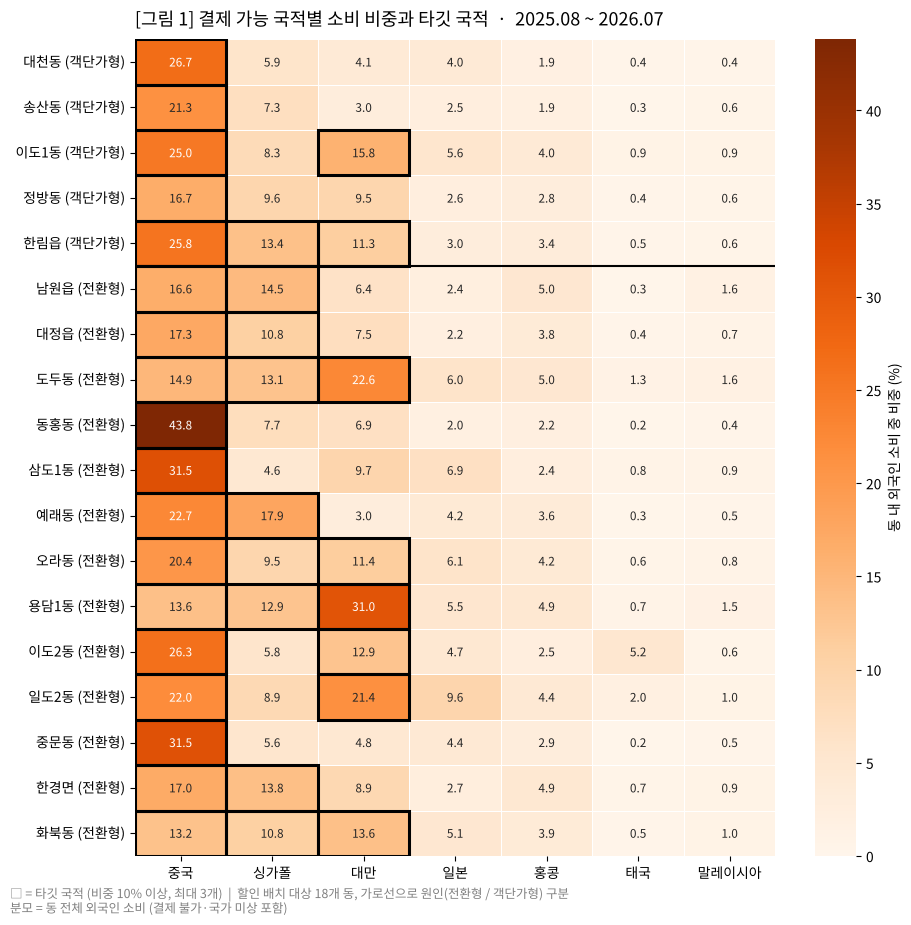

In [ ]:
COLS = DN.groupby('국가')['소비금액'].sum().sort_values(ascending=False).index.tolist()
M = DN.pivot_table(index='행정동명', columns='국가', values='비중').reindex(index=DONGS, columns=COLS)
TYPE_OF = TARGET.set_index('행정동명')['원인']
N1 = sum(TYPE_OF[d] == TYPE_OF[DONGS[0]] for d in DONGS)

fig, ax = plt.subplots(figsize=(9.5, 9))
sns.heatmap(M, annot=True, fmt='.1f', annot_kws={'fontsize': 8.5}, cmap='Oranges', vmin=0, linewidths=0.5, linecolor='white',
            cbar_kws={'label': '동 내 외국인 소비 중 비중 (%)'}, ax=ax)
for r in TGT.itertuples():
    ax.add_patch(Rectangle((COLS.index(r.국가), DONGS.index(r.행정동명)), 1, 1, fill=False, edgecolor='black', lw=2.2))
ax.axhline(N1, color='black', lw=1.5)
ax.set_yticks(np.arange(len(DONGS)) + 0.5); ax.set_yticklabels([f'{d} ({TYPE_OF[d]})' for d in DONGS], rotation=0)
ax.set_xlabel(''); ax.set_ylabel('')
ax.set_title(f'[그림 1] 결제 가능 국적별 소비 비중과 타깃 국적  ·  {PERIOD}', loc='left', fontsize=13, pad=10)
fig.text(0.01, -0.02, f'□ = 타깃 국적 (비중 {SHARE_CUT}% 이상, 최대 {MAX_NAT}개)  |  할인 배치 대상 18개 동, 가로선으로 원인(전환형 / 객단가형) 구분\n'
         '분모 = 동 전체 외국인 소비 (결제 불가·국가 미상 포함)', fontsize=9, color='gray')
plt.tight_layout(); plt.savefig('1-5_타깃국적.png', dpi=200, bbox_inches='tight'); plt.show()

## Step 2. 결제 근거
- 국적별로 제로페이 연동 결제앱이 어디까지 확인됐는지 표기한다 (2026.10 웹 확인 기준).
- 2026 페스타 할인 대상 여부는 **회차마다 바뀌는 설정**이라 타깃 선정 규칙에 쓰지 않는다 (참고 열로만 표시).

In [ ]:
SRC = {
    'ZP_ALI': 'ZeroPay·Alipay+ 공식 발표 (2023.08.31, BusinessWire)',
    'JEJU'  : '헤럴드경제·마이데일리 (2025.10, 제주 제로페이 해외 간편결제 연동 현황)',
    'HYVEX' : '바이라인네트워크 (2023.10, 하이벡스 연동: 일본·대만)',
}
APP = pd.DataFrame([
    ['중국',       'Alipay / Alipay+',       '앱명 확인',              'ZP_ALI, JEJU'],
    ['홍콩',       'AlipayHK',               '앱명 확인',              'ZP_ALI'],
    ['태국',       'TrueMoney',              '앱명 확인',              'ZP_ALI'],
    ['말레이시아', "Touch 'n Go eWallet",    '앱명 확인',              'ZP_ALI'],
    ['대만',       '-',                      '연동 국가 (앱명 미공개)', 'HYVEX, JEJU'],
    ['싱가폴',     '-',                      '연동 국가 (앱명 미공개)', 'JEJU'],
    ['일본',       '-',                      '연동 국가 (앱명 미공개)', 'HYVEX, JEJU'],
], columns=['국가', '결제앱', '확인수준', '출처']).set_index('국가')
APP['(참고) 2026 페스타 할인대상'] = C2.groupby('국가')['할인대상_2026페스타'].max().reindex(APP.index).eq(1).map({True: 'O', False: '-'})
APP['결제근거'] = np.where(APP['확인수준'] == '앱명 확인', APP['결제앱'], '연동 국가 (앱명 미공개)')
for k, v in SRC.items(): print(f'{k}: {v}')
display(APP)

## Step 3. 어디서: QR 설치 우선 업종 (18개 동 전부)
- 데이터: `QR_가게단위_매칭.csv` (상가 × 제로페이 가게 단위 매칭, `QR_가게매칭.ipynb`) → 가게마다 **QR 있음 / 없음**
- **관광 업종 가게만** 본다 (음식: 유흥주점·구내식당 제외 전부 / 소매: 편의점·슈퍼·소품샵·화장품·약국·기념품·의류 등)
- 동별로 **QR 없는 가게가 많은 세부 업종 TOP3** = QR을 먼저 깔 곳

In [ ]:
QT = QR[QR['행정동명'].isin(DONGS) & QR['관광업종']]

STATE = ['QR 없음', 'QR 있음']
ST = pd.crosstab(QT['행정동명'], QT['QR상태']).reindex(columns=STATE, fill_value=0)
ST['관광 가게 수'] = ST.sum(axis=1)

NOQR = (QT[QT['QR상태'] == 'QR 없음'].groupby(['행정동명', '세부업종']).size().rename('QR없음').reset_index()
          .sort_values(['행정동명', 'QR없음'], ascending=[True, False]))
TOP = NOQR.groupby('행정동명').head(TOP_IND)
TOP_STR = TOP.groupby('행정동명').apply(lambda g: ' · '.join(f'{r.세부업종} {r.QR없음}' for r in g.itertuples()), include_groups=False)

QTAB = ST.loc[DONGS].assign(**{'QR 없음 비율(%)': lambda d: d['QR 없음'] / d['관광 가게 수'] * 100,
                                f'QR 설치 우선 업종 TOP{TOP_IND}': TOP_STR.reindex(DONGS)})
display(QTAB.style.format({'QR 없음 비율(%)': '{:.0f}'}))

### 그림 2: 동별 관광 업종 가게의 QR 있음/없음

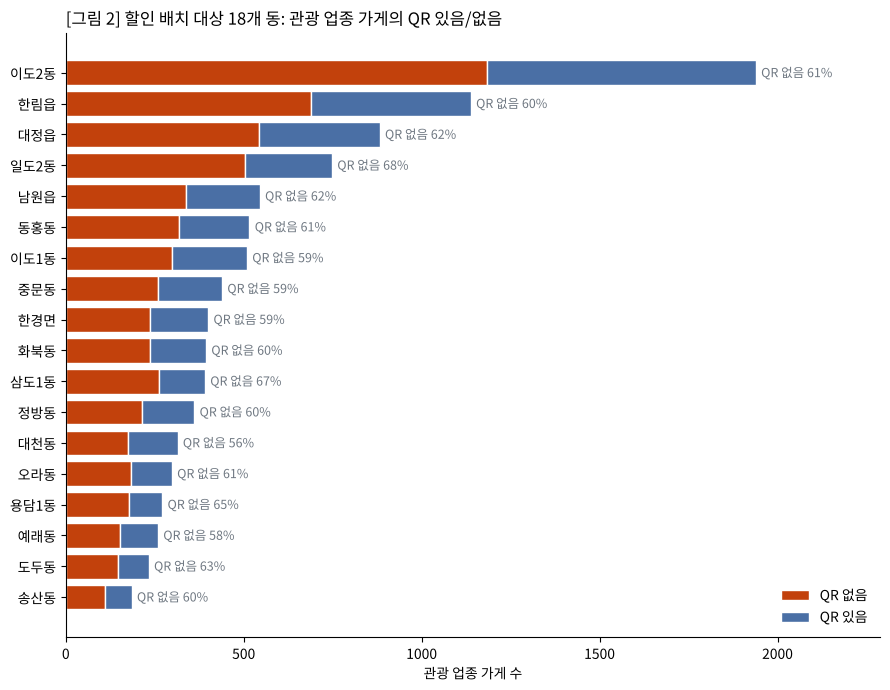

In [ ]:
COL = {'QR 없음': '#c2410c', 'QR 있음': '#4a6fa5'}
P = ST.loc[DONGS, STATE]
P = P.loc[P.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(9, 7))
left = np.zeros(len(P))
for st in STATE:
    ax.barh(P.index, P[st], left=left, color=COL[st], label=st, edgecolor='white')
    left += P[st].values
for i, d in enumerate(P.index):
    ax.text(left[i] + 15, i, f"QR 없음 {P.loc[d, 'QR 없음'] / left[i] * 100:.0f}%", va='center', fontsize=9, color='#6e7781')
ax.set_xlim(0, left.max() * 1.18)
ax.set_xlabel('관광 업종 가게 수'); ax.legend(loc='lower right', frameon=False)
ax.set_title('[그림 2] 할인 배치 대상 18개 동: 관광 업종 가게의 QR 있음/없음', loc='left', fontsize=12)
for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig('1-5_QR있음없음.png', dpi=200, bbox_inches='tight'); plt.show()

### 그림 3: 동 × 관광 업종, QR 없는 가게가 어디에 몰려 있나
- 업종: 18개 동 합계로 QR 없는 가게가 많은 관광 업종 상위 10개
- 색 = 동 안 비중 (그 동의 QR 없는 관광 가게 중 해당 업종 몫, %) → 동마다 업종 특색
- 숫자 = QR 없는 가게 수 → 실행 규모
- □ = 그 동의 QR 설치 우선 업종 TOP3

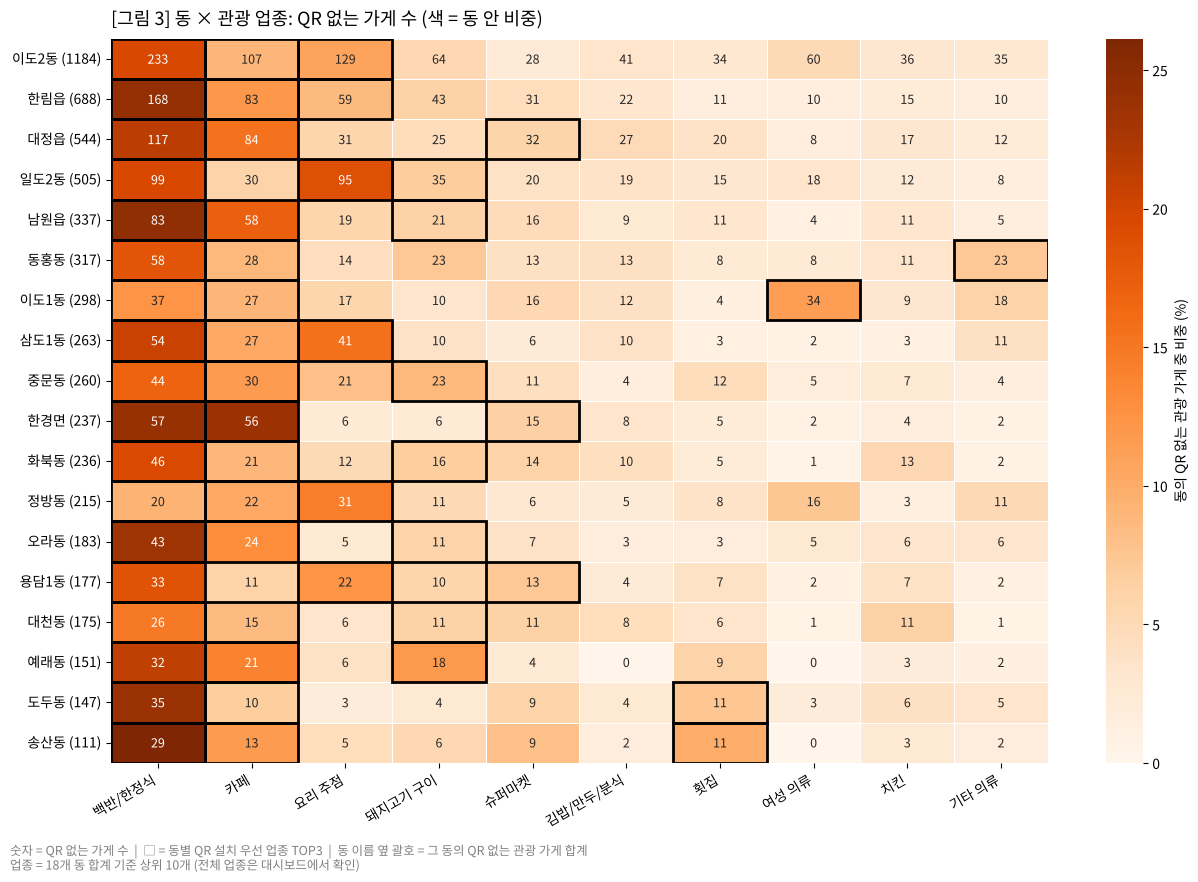

In [ ]:
N_IND = 10
TOP_INDS = NOQR.groupby('세부업종')['QR없음'].sum().sort_values(ascending=False).head(N_IND).index.tolist()
CNT = NOQR.pivot_table(index='행정동명', columns='세부업종', values='QR없음', fill_value=0)
SHR = CNT.div(ST['QR 없음'], axis=0) * 100
ROWS = ST.loc[DONGS, 'QR 없음'].sort_values(ascending=False).index.tolist()
CNT, SHR = CNT.reindex(index=ROWS, columns=TOP_INDS, fill_value=0), SHR.reindex(index=ROWS, columns=TOP_INDS, fill_value=0)

fig, ax = plt.subplots(figsize=(13, 8.5))
sns.heatmap(SHR, annot=CNT.astype(int), fmt='d', cmap='Oranges', vmin=0, linewidths=0.5, linecolor='white',
            annot_kws={'fontsize': 9}, cbar_kws={'label': '동의 QR 없는 관광 가게 중 비중 (%)'}, ax=ax)
for r in TOP.itertuples():
    if r.세부업종 in TOP_INDS:
        ax.add_patch(Rectangle((TOP_INDS.index(r.세부업종), ROWS.index(r.행정동명)), 1, 1, fill=False, edgecolor='black', lw=2))
ax.set_yticklabels([f"{d} ({ST.loc[d, 'QR 없음']})" for d in ROWS], rotation=0)
ax.set_xticklabels([c.replace(' 소매업', '').replace('돼지고기 구이/찜', '돼지고기 구이') for c in TOP_INDS], rotation=30, ha='right')
ax.set_xlabel(''); ax.set_ylabel('')
ax.set_title('[그림 3] 동 × 관광 업종: QR 없는 가게 수 (색 = 동 안 비중)', loc='left', fontsize=13, pad=10)
fig.text(0.01, -0.03, '숫자 = QR 없는 가게 수  |  □ = 동별 QR 설치 우선 업종 TOP3  |  동 이름 옆 괄호 = 그 동의 QR 없는 관광 가게 합계\n'
         '업종 = 18개 동 합계 기준 상위 10개 (전체 업종은 대시보드에서 확인)', fontsize=9, color='gray')
plt.tight_layout(); plt.savefig('1-5_QR설치우선_히트맵.png', dpi=200, bbox_inches='tight'); plt.show()

## Step 4. 동별 프로모션 배치표
- 1-4: 할인 배치 대상, 원인, 할인 설계 (어디에·어떻게)
- 1-5: 타깃 국적, 결제 근거, QR 설치 우선 업종 (누구에게·어디서)
- 할인 범위: 동 내 음식·소매 제로페이 가맹점 전체 (국적×업종 교차 데이터가 없어 국적별 업종은 특정하지 않음)
- **대시보드 연계**: 배치표의 QR 설치 우선 업종을 누르면 그 동의 **QR 없는 가게가 지도에 표시**된다 (예: 한림읍 "백반/한정식 168" → 168곳의 위치·상호). `QR_가게단위_매칭.csv`의 위경도 사용

In [ ]:
def pay_basis(dong):
    nats = TGT.loc[TGT['행정동명'] == dong, '국가']
    return ', '.join(f"{n}: {APP.at[n, '결제근거']}" for n in nats)

FINAL = TARGET[['행정동명', '구분', '원인', '할인설계']].merge(
    BY_DONG[['행정동명', '타깃 국적 (비중)', '도달 비중(%)']], on='행정동명')
FINAL['결제 근거'] = FINAL['행정동명'].map(pay_basis)
FINAL[f'QR 설치 우선 업종 TOP{TOP_IND}'] = FINAL['행정동명'].map(TOP_STR)
FINAL['QR 없는 관광 가게'] = FINAL['행정동명'].map(ST['QR 없음'])
FINAL['QR 없음 비율(%)'] = (FINAL['QR 없는 관광 가게'] / FINAL['행정동명'].map(ST['관광 가게 수']) * 100).round(0)
FINAL['1-4 원래 유형(참고)'] = FINAL['행정동명'].map(TARGET.set_index('행정동명')['1-4 원래 유형(참고)'])
FINAL['도달 비중(%)'] = FINAL['도달 비중(%)'].round(1)

with pd.option_context('display.max_colwidth', None):
    display(FINAL)
FINAL.to_csv('1-5_프로모션배치표.csv', index=False, encoding='utf-8-sig')
print('저장: 1-5_프로모션배치표.csv')

### 동별 한 줄 배치안

In [ ]:
for r in FINAL.itertuples():
    print(f"■ {r.행정동명} [{r.원인}]  누구에게: {r[5]} (도달 {r[6]:.1f}%)  어떻게: {r.할인설계}\n"
          f"   어디서: QR 설치 우선 → {r[8]}  (관광 가게 중 QR 없음 {r[9]}곳, {r[10]:.0f}%)")

## Step 5. 넘겨주기
### 5-1. 3-2 예산 배분용: 동별 결제 가능 국적 규모
- `결제가능_비중(%)` = 동 외국인 소비 중 결제 가능 국적 몫 → "할인을 받을 수 있는 외국인" 규모 추정에 사용 (예: 방문 × 결제가능 비중)
- 소비 기준 비중이라 방문 기준 비중과 다를 수 있음 (국적별 방문 데이터 없음)

In [ ]:
ALL = C2.groupby('행정동명')['소비금액'].sum().rename('외국인소비_12개월')
PAY = C2[C2['국가'].isin(PAY_OK)].groupby('행정동명')['소비금액'].sum()
HAND = pd.DataFrame({'외국인소비_12개월': ALL, '결제가능_소비': PAY.reindex(ALL.index).fillna(0)})
HAND['결제가능_비중(%)'] = HAND['결제가능_소비'] / HAND['외국인소비_12개월'] * 100
HAND = HAND.join(BY_DONG.set_index('행정동명')[['타깃 국적 (비중)', '도달 비중(%)']])
HAND = P14[['행정동명', '처방유형', '방문']].join(HAND, on='행정동명')
HAND['구분'] = np.where(HAND['처방유형'].str[0].isin(['①', '②']), '할인 배치 대상', '대상 아님')
HAND = HAND.drop(columns='처방유형')
HAND.to_csv('1-5_전달_결제가능국적규모.csv', index=False, encoding='utf-8-sig')
display(HAND[HAND['행정동명'].isin(DONGS)].round(1))
print('저장: 1-5_전달_결제가능국적규모.csv (37개 동 전체, 타깃은 할인 배치 대상 18개 동만)')

### 5-2. 4-2 민감도용: 국적 기준 5% / 10% / 15%

In [ ]:
rows = []
for cut in SENS_CUTS:
    t = select_targets(cut)
    g = t.groupby('행정동명').agg(타깃=('국가', ', '.join), 국적수=('국가', 'size'), 도달=('비중', 'sum'))
    rows.append(g.add_suffix(f'_{cut}%'))
SENS = TARGET[['행정동명', '원인']].join(pd.concat(rows, axis=1), on='행정동명')
same = (SENS[f'타깃_{SENS_CUTS[0]}%'] == SENS[f'타깃_{SHARE_CUT}%']).mean(), (SENS[f'타깃_{SENS_CUTS[-1]}%'] == SENS[f'타깃_{SHARE_CUT}%']).mean()
display(SENS.round(1))
print(f'10% 기준과 타깃 조합이 같은 동 비율: 5% 기준 {same[0]:.0%}, 15% 기준 {same[1]:.0%}')
SENS.to_csv('1-5_민감도_국적기준.csv', index=False, encoding='utf-8-sig')

## 결론
- **누구에게**: 원도심·제주시는 중국 + 대만, 서귀포·서부 읍면은 중국 + 싱가폴 조합이 나타난다. 대만이 1위인 동(도두·용담1·화북)도 있다.
- **어디서**: 18개 동 모두 관광 업종 가게의 절반 이상이 QR이 없다 → 동마다 QR 설치 우선 업종 TOP3를 함께 처방하고, 대시보드에서 해당 가게 목록·지도로 연결한다.
- **배치표**: 1-4의 "어디에·어떻게"에 1-5의 "누구에게·어디서"가 붙어 동별 프로모션 배치안이 완성된다.

**한계**: 대만·싱가폴·일본은 제로페이 연동 국가로 발표됐으나 결제앱 이름이 공개되지 않아, 실행 전 확인이 필요하다.